# Experiment 7 — End-to-End Study of Autoencoders, Convolutional Autoencoders, Denoising Autoencoders and Variational Autoencoders

**CS3807 – Deep Learning Laboratory** | Shiv Nadar University Chennai
**Name:** D Kanishkarane | **Reg No:** 24011101021 | **Class & Section:** AI DS A

Dataset: MNIST (10,000 train / 2,000 test subset, as recommended in the brief).
This notebook covers all four studies: Fully Connected AE, Convolutional AE, Denoising CAE, and VAE,
along with every required plot, metric table, and inference.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from skimage.metrics import structural_similarity as ssim
import time

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3–4. Dataset and Experimental Setup

Loading MNIST, normalizing pixel values to [0,1], and taking the recommended laboratory subset
(10,000 training images, 2,000 test images). We keep both a flattened version (784,) for the
fully connected AE and an image version (28,28,1) for the convolutional models.

In [2]:
(x_train_full, y_train_full), (x_test_full, y_test_full) = keras.datasets.mnist.load_data()

# Normalize to [0,1]
x_train_full = x_train_full.astype('float32') / 255.0
x_test_full = x_test_full.astype('float32') / 255.0

# Recommended laboratory subset
N_TRAIN, N_TEST = 10000, 2000
idx_train = np.random.choice(len(x_train_full), N_TRAIN, replace=False)
idx_test = np.random.choice(len(x_test_full), N_TEST, replace=False)

x_train_img = x_train_full[idx_train][..., np.newaxis]   # (N,28,28,1)
x_test_img = x_test_full[idx_test][..., np.newaxis]
y_train = y_train_full[idx_train]
y_test = y_test_full[idx_test]

x_train_flat = x_train_img.reshape(N_TRAIN, 784)
x_test_flat = x_test_img.reshape(N_TEST, 784)

print("Train image shape:", x_train_img.shape, "| Train flat shape:", x_train_flat.shape)
print("Test image shape:", x_test_img.shape, "| Test flat shape:", x_test_flat.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Train image shape: (10000, 28, 28, 1) | Train flat shape: (10000, 784)
Test image shape: (2000, 28, 28, 1) | Test flat shape: (2000, 784)


In [3]:
def compute_metrics(originals, reconstructions):
    """originals, reconstructions: (N,28,28,1) or (N,28,28), values in [0,1]"""
    o = originals.reshape(len(originals), 28, 28)
    r = reconstructions.reshape(len(reconstructions), 28, 28)
    mse = np.mean((o - r) ** 2)
    mae = np.mean(np.abs(o - r))
    ssim_vals = [ssim(o[i], r[i], data_range=1.0) for i in range(len(o))]
    return mse, mae, np.mean(ssim_vals)

def per_image_error(originals, reconstructions):
    o = originals.reshape(len(originals), -1)
    r = reconstructions.reshape(len(reconstructions), -1)
    return np.mean((o - r) ** 2, axis=1)

results_table = {}  # model_name -> dict(mse, mae, ssim, params, time)

## 6–7. Fully Connected Autoencoder

Encoder: 784 → 128 → 32 → **16 (latent)**. Decoder mirrors this back to 784.
ReLU in hidden layers, sigmoid on the output (since pixels are in [0,1]).

In [4]:
def build_fc_autoencoder(latent_dim=16):
    inputs = keras.Input(shape=(784,))
    x = layers.Dense(128, activation='relu')(inputs)
    x = layers.Dense(32, activation='relu')(x)
    z = layers.Dense(latent_dim, activation='relu', name='latent')(x)
    x = layers.Dense(32, activation='relu')(z)
    x = layers.Dense(128, activation='relu')(x)
    outputs = layers.Dense(784, activation='sigmoid')(x)
    return keras.Model(inputs, outputs, name=f'FC_AE_dim{latent_dim}')

fc_ae = build_fc_autoencoder(latent_dim=16)
fc_ae.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss='binary_crossentropy')
fc_ae.summary()

Model: "FC_AE_dim16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 211,040 (824.38 KB)

 Trainable params: 211,040 (824.38 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
t0 = time.time()
history_fc = fc_ae.fit(x_train_flat, x_train_flat,
                        validation_data=(x_test_flat, x_test_flat),
                        epochs=20, batch_size=128, verbose=2)
fc_train_time = time.time() - t0
print(f"FC-AE training time: {fc_train_time:.1f}s")

Epoch 1/20
79/79 - 5s - 64ms/step - loss: 0.3478 - val_loss: 0.2642
Epoch 2/20
79/79 - 0s - 4ms/step - loss: 0.2461 - val_loss: 0.2265
Epoch 3/20
79/79 - 0s - 4ms/step - loss: 0.2154 - val_loss: 0.2000
Epoch 4/20
79/79 - 0s - 4ms/step - loss: 0.1879 - val_loss: 0.1760
Epoch 5/20
79/79 - 0s - 6ms/step - loss: 0.1726 - val_loss: 0.1677
Epoch 6/20
79/79 - 0s - 6ms/step - loss: 0.1651 - val_loss: 0.1608
Epoch 7/20
79/79 - 0s - 6ms/step - loss: 0.1593 - val_loss: 0.1561
Epoch 8/20
79/79 - 1s - 7ms/step - loss: 0.1551 - val_loss: 0.1521
Epoch 9/20
79/79 - 0s - 5ms/step - loss: 0.1511 - val_loss: 0.1480
Epoch 10/20
79/79 - 0s - 5ms/step - loss: 0.1471 - val_loss: 0.1442
Epoch 11/20
79/79 - 0s - 6ms/step - loss: 0.1436 - val_loss: 0.1413
Epoch 12/20
79/79 - 0s - 6ms/step - loss: 0.1408 - val_loss: 0.1387
Epoch 13/20
79/79 - 0s - 6ms/step - loss: 0.1385 - val_loss: 0.1365
Epoch 14/20
79/79 - 0s - 4ms/step - loss: 0.1364 - val_loss: 0.1344
Epoch 15/20
79/79 - 0s - 4ms/step - loss: 0.1344 - val_l

## 8. Required Analysis of the Basic Autoencoder

**Plot 1: Original vs Reconstructed** and **Plot 2: Training/Validation Loss.**

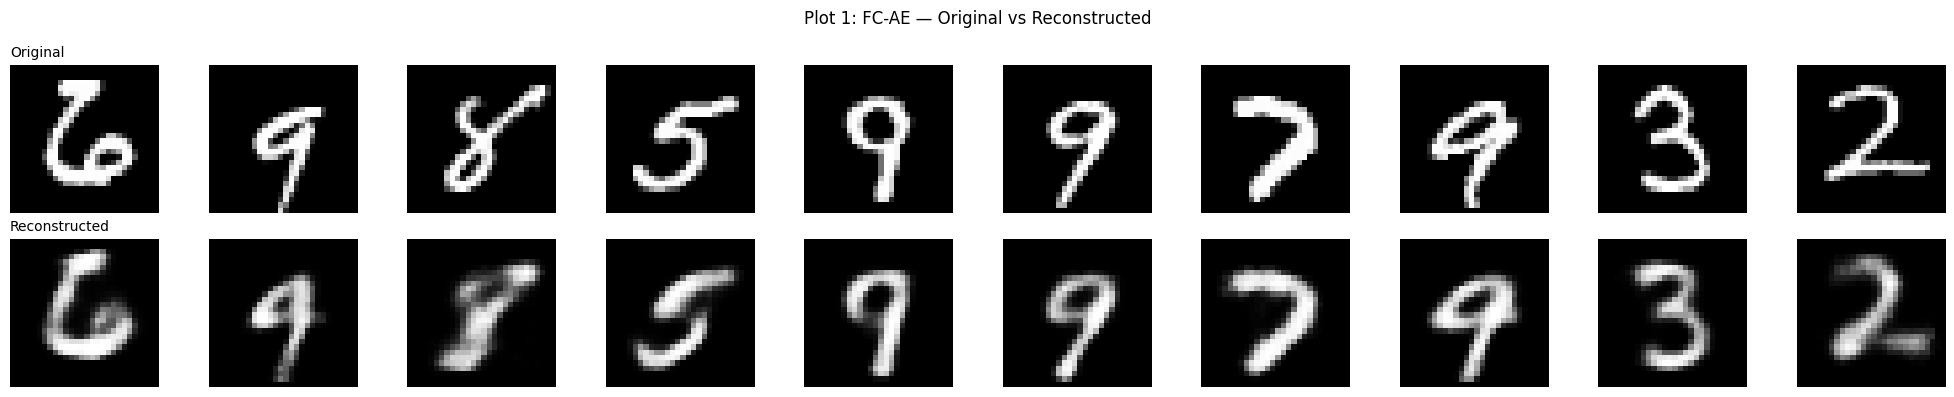

In [6]:
recon_fc_test = fc_ae.predict(x_test_flat, verbose=0)

n_show = 10
fig, axes = plt.subplots(2, n_show, figsize=(20, 4))
for i in range(n_show):
    axes[0, i].imshow(x_test_flat[i].reshape(28, 28), cmap='gray')
    axes[0, i].axis('off')
    axes[1, i].imshow(recon_fc_test[i].reshape(28, 28), cmap='gray')
    axes[1, i].axis('off')
axes[0, 0].set_title('Original', loc='left', fontsize=10)
axes[1, 0].set_title('Reconstructed', loc='left', fontsize=10)
plt.suptitle('Plot 1: FC-AE — Original vs Reconstructed')
plt.tight_layout()
plt.savefig('plot1_fc_original_vs_recon.png', dpi=150)
plt.show()

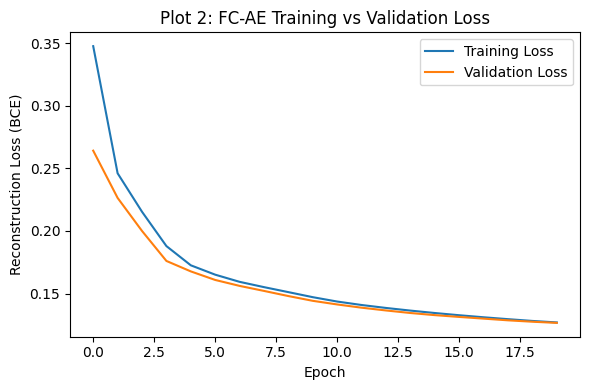

In [7]:
plt.figure(figsize=(6, 4))
plt.plot(history_fc.history['loss'], label='Training Loss')
plt.plot(history_fc.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Reconstruction Loss (BCE)')
plt.title('Plot 2: FC-AE Training vs Validation Loss')
plt.legend()
plt.tight_layout()
plt.savefig('plot2_fc_loss_curve.png', dpi=150)
plt.show()

**Inference (Plot 1 & 2):** Fill in after running — comment on whether digit shape/topology is preserved,
where fine detail (loops, stroke thickness) is lost or blurred, and whether easy digits (0, 1) reconstruct
cleaner than complex ones (8, 5). For the loss curve, state whether train/val loss converge close together
(no overfitting, since the model is small and the dataset subset is reasonably sized) or diverge.

## 9. Reconstruction Metrics (FC-AE)

In [8]:
mse_fc, mae_fc, ssim_fc = compute_metrics(x_test_img, recon_fc_test)
fc_params = fc_ae.count_params()
results_table['FC Autoencoder'] = dict(mse=mse_fc, mae=mae_fc, ssim=ssim_fc, params=fc_params, time=fc_train_time)
print(f"Test MSE:  {mse_fc:.5f}")
print(f"Test MAE:  {mae_fc:.5f}")
print(f"Mean SSIM: {ssim_fc:.5f}")

Test MSE:  0.02128
Test MAE:  0.05694
Mean SSIM: 0.76012


## 10. Convolutional Autoencoder

Preserves spatial structure via Conv2D + MaxPooling2D in the encoder and Conv2D + UpSampling2D
in the decoder, as specified in the brief.

In [9]:
def build_cae():
    inputs = keras.Input(shape=(28, 28, 1))
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(inputs)
    x = layers.MaxPooling2D(2, padding='same')(x)
    x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
    x = layers.MaxPooling2D(2, padding='same')(x)
    x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)   # latent feature map (7x7x64)
    x = layers.UpSampling2D(2)(x)
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(x)
    x = layers.UpSampling2D(2)(x)
    outputs = layers.Conv2D(1, 3, activation='sigmoid', padding='same')(x)
    return keras.Model(inputs, outputs, name='Conv_AE')

cae = build_cae()
cae.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss='binary_crossentropy')
cae.summary()

Model: "Conv_AE"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 74,497 (291.00 KB)

 Trainable params: 74,497 (291.00 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
t0 = time.time()
history_cae = cae.fit(x_train_img, x_train_img,
                       validation_data=(x_test_img, x_test_img),
                       epochs=20, batch_size=128, verbose=2)
cae_train_time = time.time() - t0
print(f"CAE training time: {cae_train_time:.1f}s")

Epoch 1/20
79/79 - 9s - 108ms/step - loss: 0.2298 - val_loss: 0.1009
Epoch 2/20
79/79 - 4s - 46ms/step - loss: 0.0915 - val_loss: 0.0864
Epoch 3/20
79/79 - 1s - 7ms/step - loss: 0.0831 - val_loss: 0.0805
Epoch 4/20
79/79 - 1s - 7ms/step - loss: 0.0793 - val_loss: 0.0800
Epoch 5/20
79/79 - 1s - 7ms/step - loss: 0.0771 - val_loss: 0.0760
Epoch 6/20
79/79 - 1s - 7ms/step - loss: 0.0755 - val_loss: 0.0753
Epoch 7/20
79/79 - 1s - 8ms/step - loss: 0.0744 - val_loss: 0.0741
Epoch 8/20
79/79 - 1s - 8ms/step - loss: 0.0735 - val_loss: 0.0726
Epoch 9/20
79/79 - 1s - 7ms/step - loss: 0.0729 - val_loss: 0.0730
Epoch 10/20
79/79 - 1s - 8ms/step - loss: 0.0722 - val_loss: 0.0722
Epoch 11/20
79/79 - 1s - 8ms/step - loss: 0.0717 - val_loss: 0.0713
Epoch 12/20
79/79 - 1s - 9ms/step - loss: 0.0713 - val_loss: 0.0710
Epoch 13/20
79/79 - 1s - 9ms/step - loss: 0.0708 - val_loss: 0.0705
Epoch 14/20
79/79 - 1s - 15ms/step - loss: 0.0705 - val_loss: 0.0702
Epoch 15/20
79/79 - 1s - 7ms/step - loss: 0.0701 - va

## 11. Comparing Fully Connected and Convolutional Autoencoders — Plot 3

In [11]:
recon_cae_test = cae.predict(x_test_img, verbose=0)
mse_cae, mae_cae, ssim_cae = compute_metrics(x_test_img, recon_cae_test)
cae_params = cae.count_params()
results_table['Convolutional AE'] = dict(mse=mse_cae, mae=mae_cae, ssim=ssim_cae, params=cae_params, time=cae_train_time)

print(f"{'Model':<20}{'MSE':>10}{'MAE':>10}{'SSIM':>10}{'Params':>12}")
for name, r in results_table.items():
    print(f"{name:<20}{r['mse']:>10.5f}{r['mae']:>10.5f}{r['ssim']:>10.5f}{r['params']:>12,}")

Model                      MSE       MAE      SSIM      Params
FC Autoencoder         0.02128   0.05694   0.76012     211,040
Convolutional AE       0.00265   0.01564   0.97209      74,497


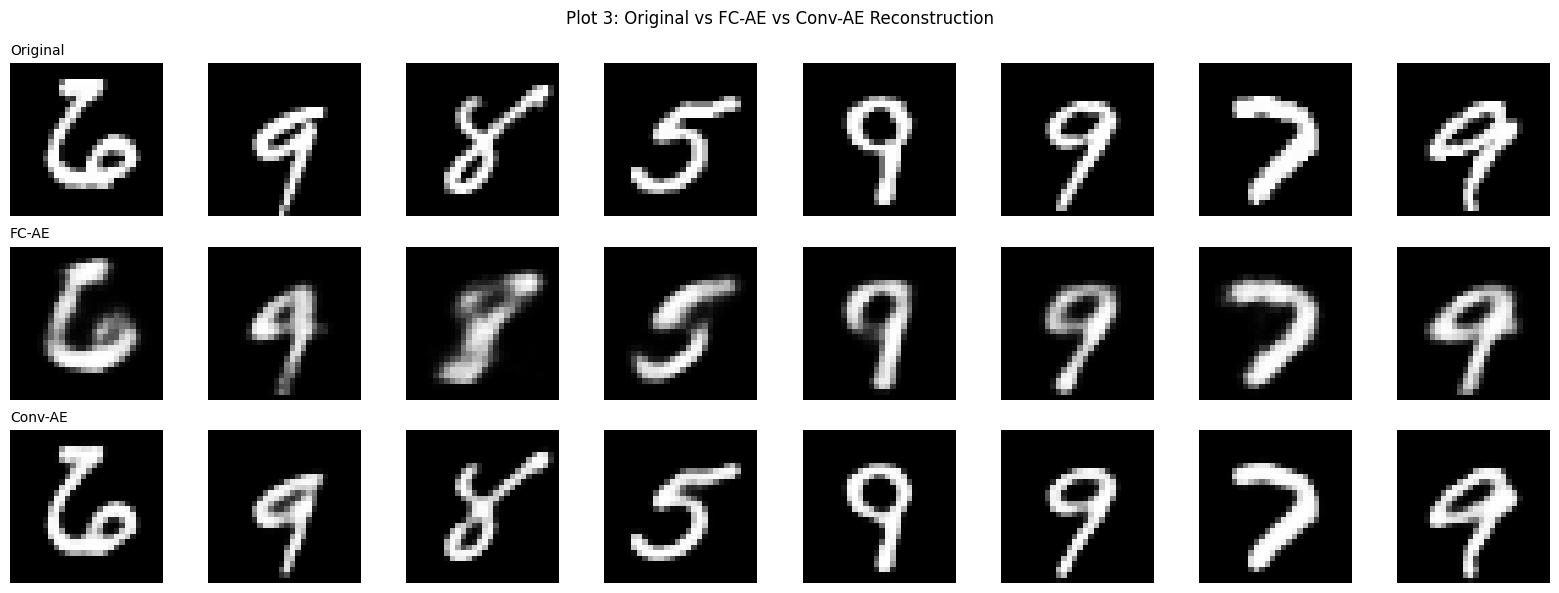

In [12]:
n_show = 8
fig, axes = plt.subplots(3, n_show, figsize=(16, 6))
for i in range(n_show):
    axes[0, i].imshow(x_test_img[i].reshape(28, 28), cmap='gray'); axes[0, i].axis('off')
    axes[1, i].imshow(recon_fc_test[i].reshape(28, 28), cmap='gray'); axes[1, i].axis('off')
    axes[2, i].imshow(recon_cae_test[i].reshape(28, 28), cmap='gray'); axes[2, i].axis('off')
axes[0, 0].set_title('Original', loc='left', fontsize=10)
axes[1, 0].set_title('FC-AE', loc='left', fontsize=10)
axes[2, 0].set_title('Conv-AE', loc='left', fontsize=10)
plt.suptitle('Plot 3: Original vs FC-AE vs Conv-AE Reconstruction')
plt.tight_layout()
plt.savefig('plot3_fc_vs_cae.png', dpi=150)
plt.show()

**Inference (Plot 3):** Fill in after running — the CAE typically produces sharper edges and better-preserved
stroke continuity than the FC-AE because convolution filters exploit spatial locality (neighbouring pixels are
correlated), whereas flattening in the FC-AE destroys that 2D neighbourhood structure before the network ever
sees it. Compare the MSE/SSIM numbers printed above to support the claim quantitatively.

## 12–13. Denoising Autoencoder

Input is a corrupted image x̃, but the training target remains the **clean** image x. We implement both
required corruption types — Gaussian noise and salt-and-pepper noise — and train the denoising model
using Gaussian noise (σ = 0.2) as the primary corruption, then evaluate robustness across noise levels.

In [13]:
def add_gaussian_noise(images, sigma):
    noisy = images + np.random.normal(0, sigma, images.shape)
    return np.clip(noisy, 0.0, 1.0).astype('float32')

def add_salt_pepper_noise(images, p):
    noisy = images.copy()
    mask = np.random.rand(*images.shape)
    noisy[mask < p / 2] = 0.0
    noisy[(mask >= p / 2) & (mask < p)] = 1.0
    return noisy.astype('float32')

# Primary training corruption
SIGMA_TRAIN = 0.2
x_train_noisy = add_gaussian_noise(x_train_img, SIGMA_TRAIN)
x_test_noisy = add_gaussian_noise(x_test_img, SIGMA_TRAIN)

In [14]:
def build_denoising_cae():
    # Same architecture as the Conv-AE
    return build_cae()

dcae = build_denoising_cae()
dcae._name = 'Denoising_CAE'
dcae.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss='binary_crossentropy')

t0 = time.time()
history_dcae = dcae.fit(x_train_noisy, x_train_img,          # input=noisy, target=clean
                         validation_data=(x_test_noisy, x_test_img),
                         epochs=20, batch_size=128, verbose=2)
dcae_train_time = time.time() - t0
print(f"Denoising CAE training time: {dcae_train_time:.1f}s")

Epoch 1/20
79/79 - 6s - 80ms/step - loss: 0.2633 - val_loss: 0.1229
Epoch 2/20
79/79 - 1s - 9ms/step - loss: 0.1068 - val_loss: 0.0964
Epoch 3/20
79/79 - 1s - 7ms/step - loss: 0.0940 - val_loss: 0.0899
Epoch 4/20
79/79 - 1s - 8ms/step - loss: 0.0891 - val_loss: 0.0876
Epoch 5/20
79/79 - 1s - 7ms/step - loss: 0.0863 - val_loss: 0.0843
Epoch 6/20
79/79 - 1s - 8ms/step - loss: 0.0845 - val_loss: 0.0825
Epoch 7/20
79/79 - 1s - 8ms/step - loss: 0.0829 - val_loss: 0.0813
Epoch 8/20
79/79 - 1s - 8ms/step - loss: 0.0817 - val_loss: 0.0803
Epoch 9/20
79/79 - 1s - 8ms/step - loss: 0.0807 - val_loss: 0.0795
Epoch 10/20
79/79 - 1s - 7ms/step - loss: 0.0799 - val_loss: 0.0788
Epoch 11/20
79/79 - 1s - 8ms/step - loss: 0.0793 - val_loss: 0.0782
Epoch 12/20
79/79 - 1s - 8ms/step - loss: 0.0787 - val_loss: 0.0777
Epoch 13/20
79/79 - 1s - 8ms/step - loss: 0.0781 - val_loss: 0.0773
Epoch 14/20
79/79 - 1s - 8ms/step - loss: 0.0776 - val_loss: 0.0769
Epoch 15/20
79/79 - 1s - 7ms/step - loss: 0.0772 - val_l

## 14. Required Denoising Plots — Plot 4: Clean vs Noisy vs Denoised

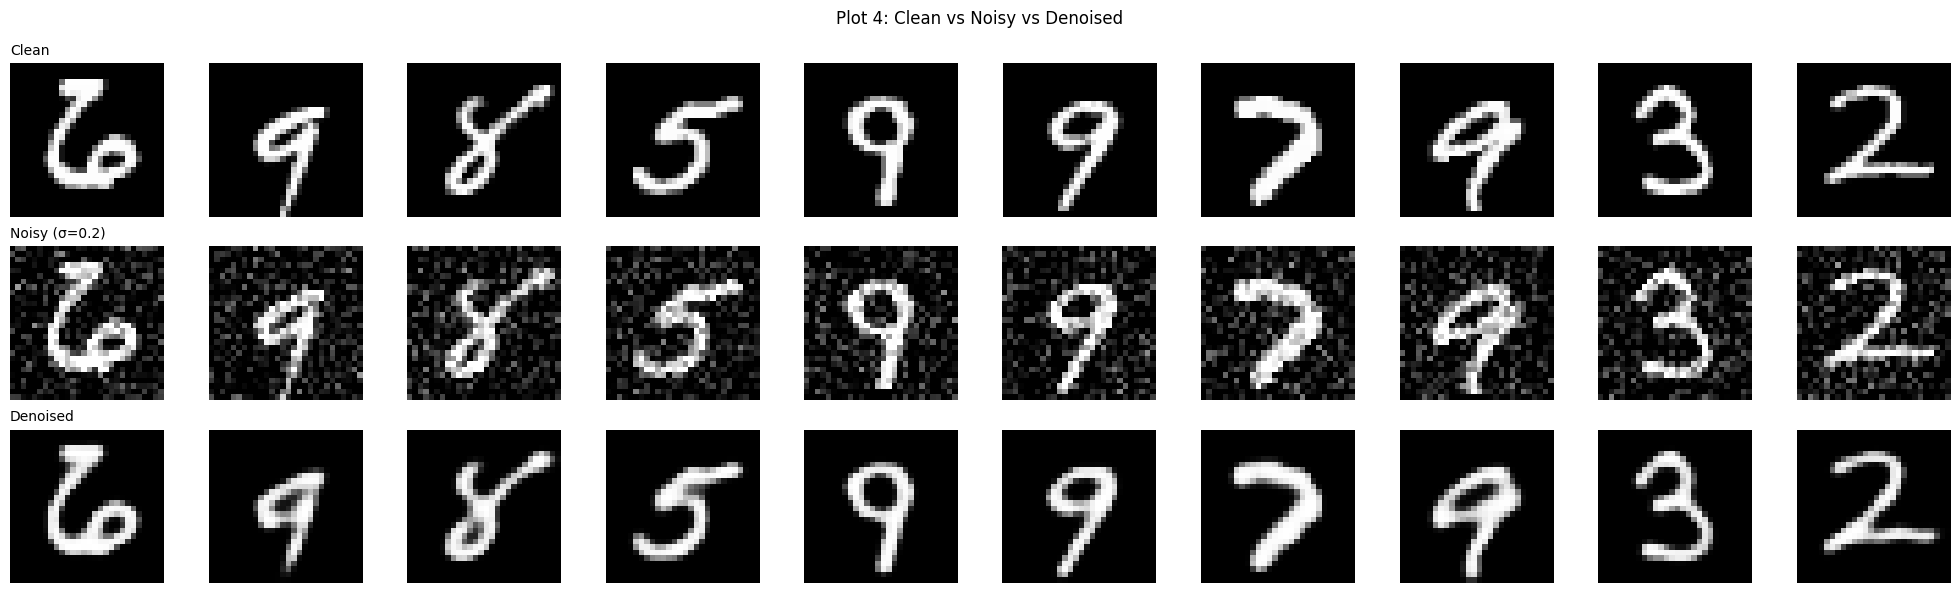

In [15]:
denoised_test = dcae.predict(x_test_noisy, verbose=0)

n_show = 10
fig, axes = plt.subplots(3, n_show, figsize=(20, 6))
for i in range(n_show):
    axes[0, i].imshow(x_test_img[i].reshape(28, 28), cmap='gray'); axes[0, i].axis('off')
    axes[1, i].imshow(x_test_noisy[i].reshape(28, 28), cmap='gray'); axes[1, i].axis('off')
    axes[2, i].imshow(denoised_test[i].reshape(28, 28), cmap='gray'); axes[2, i].axis('off')
axes[0, 0].set_title('Clean', loc='left', fontsize=10)
axes[1, 0].set_title('Noisy (σ=0.2)', loc='left', fontsize=10)
axes[2, 0].set_title('Denoised', loc='left', fontsize=10)
plt.suptitle('Plot 4: Clean vs Noisy vs Denoised')
plt.tight_layout()
plt.savefig('plot4_denoising.png', dpi=150)
plt.show()

### Salt-and-pepper noise — second corruption type (qualitative check)
The brief requires at least two corruption types. We demonstrate salt-and-pepper corruption on the same
trained denoising model to see how well a model trained only on Gaussian noise generalizes to a different
noise family (it typically struggles more, since it never saw impulse noise during training).

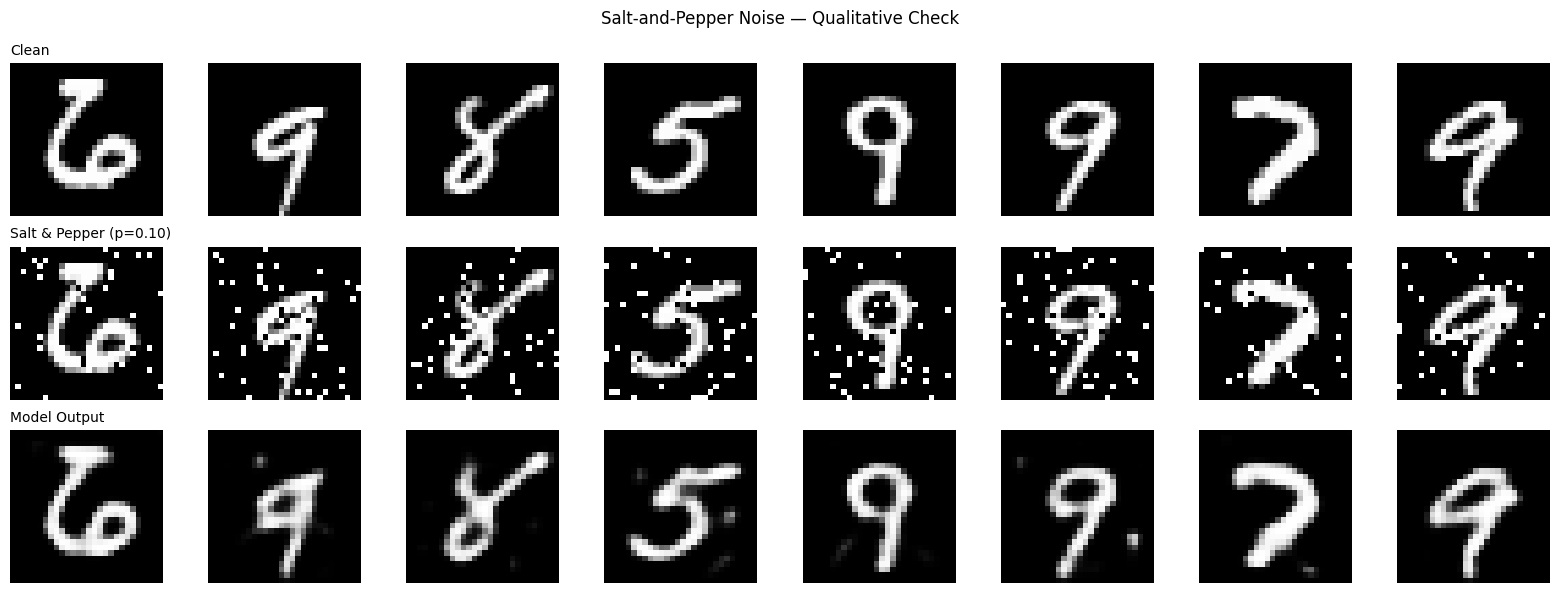

In [16]:
x_test_sp = add_salt_pepper_noise(x_test_img, p=0.10)
denoised_sp = dcae.predict(x_test_sp, verbose=0)

n_show = 8
fig, axes = plt.subplots(3, n_show, figsize=(16, 6))
for i in range(n_show):
    axes[0, i].imshow(x_test_img[i].reshape(28, 28), cmap='gray'); axes[0, i].axis('off')
    axes[1, i].imshow(x_test_sp[i].reshape(28, 28), cmap='gray'); axes[1, i].axis('off')
    axes[2, i].imshow(denoised_sp[i].reshape(28, 28), cmap='gray'); axes[2, i].axis('off')
axes[0, 0].set_title('Clean', loc='left', fontsize=10)
axes[1, 0].set_title('Salt & Pepper (p=0.10)', loc='left', fontsize=10)
axes[2, 0].set_title('Model Output', loc='left', fontsize=10)
plt.suptitle('Salt-and-Pepper Noise — Qualitative Check')
plt.tight_layout()
plt.savefig('plot4b_saltpepper.png', dpi=150)
plt.show()

## Plot 5: Noise Level vs Reconstruction Quality (Gaussian)

Noise Level           MSE       MAE      SSIM
0.1               0.00360   0.01791   0.96061
0.2               0.00459   0.02136   0.94731
0.3               0.00709   0.02934   0.88391


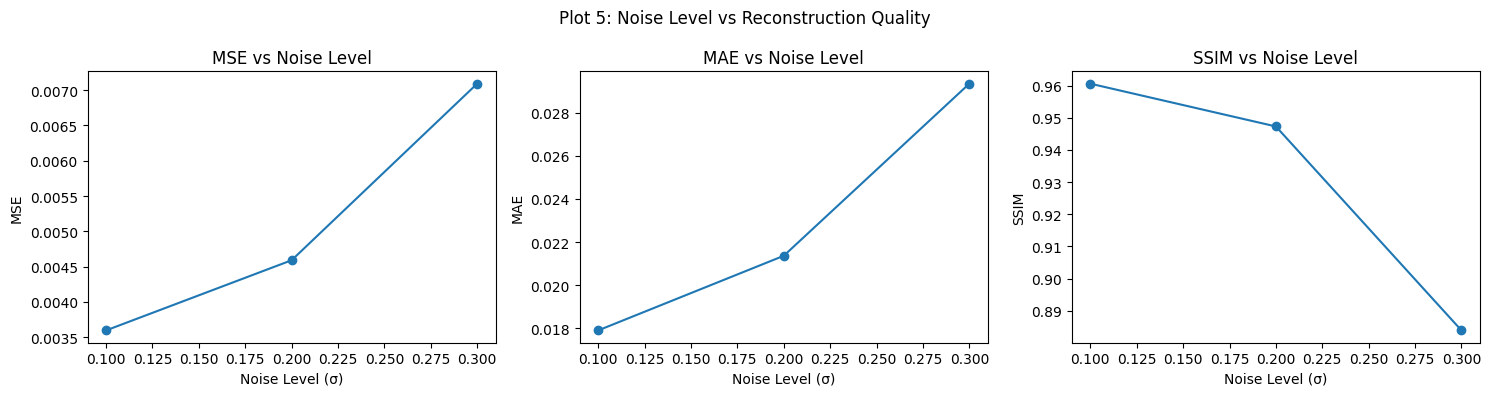

In [17]:
noise_levels = [0.1, 0.2, 0.3]
noise_level_results = {}
for sigma in noise_levels:
    x_noisy_eval = add_gaussian_noise(x_test_img, sigma)
    recon = dcae.predict(x_noisy_eval, verbose=0)
    mse_n, mae_n, ssim_n = compute_metrics(x_test_img, recon)
    noise_level_results[sigma] = dict(mse=mse_n, mae=mae_n, ssim=ssim_n)

print(f"{'Noise Level':<15}{'MSE':>10}{'MAE':>10}{'SSIM':>10}")
for sigma, r in noise_level_results.items():
    print(f"{sigma:<15}{r['mse']:>10.5f}{r['mae']:>10.5f}{r['ssim']:>10.5f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
metrics_names = ['mse', 'mae', 'ssim']
for ax, m in zip(axes, metrics_names):
    vals = [noise_level_results[s][m] for s in noise_levels]
    ax.plot(noise_levels, vals, marker='o')
    ax.set_xlabel('Noise Level (σ)')
    ax.set_ylabel(m.upper())
    ax.set_title(f'{m.upper()} vs Noise Level')
plt.suptitle('Plot 5: Noise Level vs Reconstruction Quality')
plt.tight_layout()
plt.savefig('plot5_noise_vs_quality.png', dpi=150)
plt.show()

mse_dcae, mae_dcae, ssim_dcae = compute_metrics(x_test_img, denoised_test)
dcae_params = dcae.count_params()
results_table['Denoising CAE'] = dict(mse=mse_dcae, mae=mae_dcae, ssim=ssim_dcae, params=dcae_params, time=dcae_train_time)

**Inference (Plots 4 & 5):** Fill in after running — as σ increases, MSE/MAE rise and SSIM falls, since more
of the original signal is destroyed before the encoder ever sees it. The model still recovers the overall digit
*shape* at moderate noise levels because the bottleneck forces it to rely on learned digit priors rather than
copying pixels directly, but fine stroke detail degrades first. Note whether the salt-and-pepper case is
noticeably worse than Gaussian at a similar visual corruption level — that would indicate the model has
overfit to the specific noise distribution it was trained on.

## 15–17. Variational Autoencoder

Instead of a deterministic latent vector, the encoder produces a distribution q(z|x) = N(μ(x), σ²(x)).
We use the **reparameterization trick** z = μ + σ⊙ε (ε ~ N(0,I)) so gradients can flow through the
sampling step. Latent dimension is kept at **2** so the latent space can be visualized directly.

In [18]:
class Sampling(layers.Layer):
    """z = mu + sigma * epsilon"""
    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = tf.shape(z_mean)[0]
        dim = tf.shape(z_mean)[1]
        epsilon = tf.random.normal(shape=(batch, dim))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

VAE_LATENT_DIM = 2

# --- Encoder ---
enc_inputs = keras.Input(shape=(28, 28, 1))
x = layers.Conv2D(32, 3, activation='relu', strides=2, padding='same')(enc_inputs)
x = layers.Conv2D(64, 3, activation='relu', strides=2, padding='same')(x)
x = layers.Flatten()(x)
x = layers.Dense(64, activation='relu')(x)
z_mean = layers.Dense(VAE_LATENT_DIM, name='z_mean')(x)
z_log_var = layers.Dense(VAE_LATENT_DIM, name='z_log_var')(x)
z = Sampling()([z_mean, z_log_var])
vae_encoder = keras.Model(enc_inputs, [z_mean, z_log_var, z], name='vae_encoder')
vae_encoder.summary()

Model: "vae_encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 14, 14,    │        320 │ input_layer_3[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 7, 7, 64)  │     18,496 │ conv2d_10[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 3136)      │          0 │ conv2d_11[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 64)        │    200,768 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 2)         │        130 │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 2)         │        130 │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 2)         │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 219,844 (858.77 KB)

 Trainable params: 219,844 (858.77 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
# --- Decoder ---
dec_inputs = keras.Input(shape=(VAE_LATENT_DIM,))
x = layers.Dense(7 * 7 * 64, activation='relu')(dec_inputs)
x = layers.Reshape((7, 7, 64))(x)
x = layers.Conv2DTranspose(64, 3, activation='relu', strides=2, padding='same')(x)
x = layers.Conv2DTranspose(32, 3, activation='relu', strides=2, padding='same')(x)
dec_outputs = layers.Conv2DTranspose(1, 3, activation='sigmoid', padding='same')(x)
vae_decoder = keras.Model(dec_inputs, dec_outputs, name='vae_decoder')
vae_decoder.summary()

Model: "vae_decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 3136)           │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │        36,928 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 1)      │           289 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 65,089 (254.25 KB)

 Trainable params: 65,089 (254.25 KB)

 Non-trainable params: 0 (0.00 B)

## 16. VAE Loss Function — Reconstruction + KL Divergence

In [20]:
class VAE(keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.total_loss_tracker = keras.metrics.Mean(name='total_loss')
        self.recon_loss_tracker = keras.metrics.Mean(name='reconstruction_loss')
        self.kl_loss_tracker = keras.metrics.Mean(name='kl_loss')

    @property
    def metrics(self):
        return [self.total_loss_tracker, self.recon_loss_tracker, self.kl_loss_tracker]

    def train_step(self, data):
        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(data)
            reconstruction = self.decoder(z)
            recon_loss = tf.reduce_mean(
                tf.reduce_sum(
                    keras.losses.binary_crossentropy(data, reconstruction),
                    axis=(1, 2)
                )
            )
            kl_loss = -0.5 * (1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var))
            kl_loss = tf.reduce_mean(tf.reduce_sum(kl_loss, axis=1))
            total_loss = recon_loss + kl_loss
        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        self.total_loss_tracker.update_state(total_loss)
        self.recon_loss_tracker.update_state(recon_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {m.name: m.result() for m in self.metrics}

    def test_step(self, data):
        z_mean, z_log_var, z = self.encoder(data)
        reconstruction = self.decoder(z)
        recon_loss = tf.reduce_mean(
            tf.reduce_sum(keras.losses.binary_crossentropy(data, reconstruction), axis=(1, 2))
        )
        kl_loss = -0.5 * (1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var))
        kl_loss = tf.reduce_mean(tf.reduce_sum(kl_loss, axis=1))
        total_loss = recon_loss + kl_loss
        self.total_loss_tracker.update_state(total_loss)
        self.recon_loss_tracker.update_state(recon_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {m.name: m.result() for m in self.metrics}

In [21]:
vae = VAE(vae_encoder, vae_decoder)
vae.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3))

t0 = time.time()
history_vae = vae.fit(x_train_img, epochs=20, batch_size=128,
                       validation_data=(x_test_img, None), verbose=2)
vae_train_time = time.time() - t0
print(f"VAE training time: {vae_train_time:.1f}s")

Epoch 1/20
79/79 - 12s - 150ms/step - kl_loss: 2.9785 - reconstruction_loss: 290.4277 - total_loss: 293.4062 - val_kl_loss: 2.3675 - val_reconstruction_loss: 207.6988 - val_total_loss: 210.0663
Epoch 2/20
79/79 - 1s - 7ms/step - kl_loss: 3.2292 - reconstruction_loss: 199.2245 - total_loss: 202.4537 - val_kl_loss: 3.7206 - val_reconstruction_loss: 194.8043 - val_total_loss: 198.5248
Epoch 3/20
79/79 - 1s - 7ms/step - kl_loss: 3.4986 - reconstruction_loss: 193.2835 - total_loss: 196.7821 - val_kl_loss: 3.4925 - val_reconstruction_loss: 190.9190 - val_total_loss: 194.4115
Epoch 4/20
79/79 - 1s - 7ms/step - kl_loss: 4.5808 - reconstruction_loss: 183.2050 - total_loss: 187.7858 - val_kl_loss: 4.7431 - val_reconstruction_loss: 178.0568 - val_total_loss: 182.8000
Epoch 5/20
79/79 - 1s - 7ms/step - kl_loss: 4.8505 - reconstruction_loss: 175.3310 - total_loss: 180.1815 - val_kl_loss: 4.8826 - val_reconstruction_loss: 173.5565 - val_total_loss: 178.4391
Epoch 6/20
79/79 - 1s - 7ms/step - kl_loss

### Plot 9 (VAE): Training/Validation Reconstruction Loss (required plot #9 in the brief)

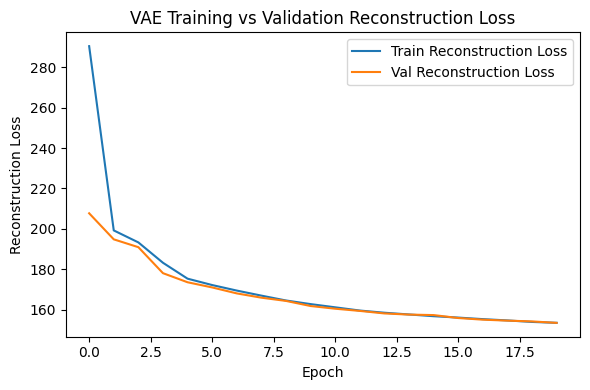

In [22]:
plt.figure(figsize=(6, 4))
plt.plot(history_vae.history['reconstruction_loss'], label='Train Reconstruction Loss')
plt.plot(history_vae.history['val_reconstruction_loss'], label='Val Reconstruction Loss')
plt.xlabel('Epoch'); plt.ylabel('Reconstruction Loss')
plt.title('VAE Training vs Validation Reconstruction Loss')
plt.legend(); plt.tight_layout()
plt.savefig('plot9_vae_loss_curve.png', dpi=150)
plt.show()

## 18. Exploring the VAE Latent Space — Plot 6

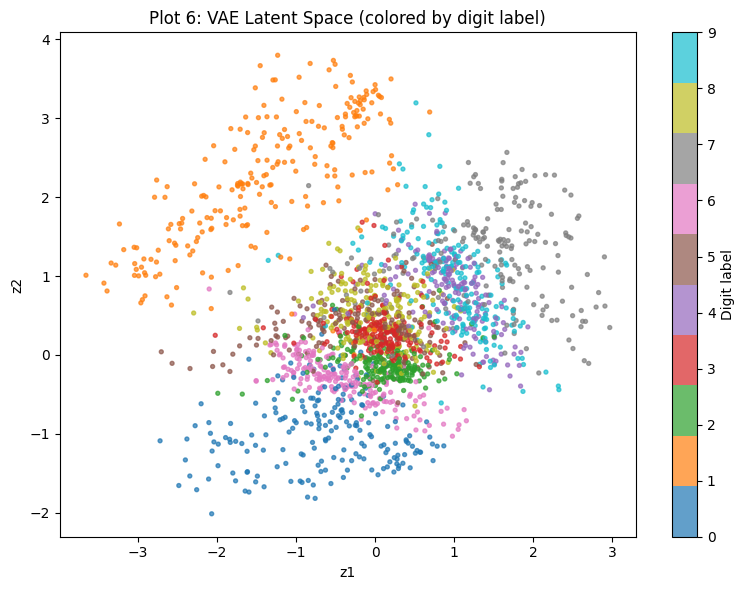

In [23]:
z_mean_test, z_log_var_test, _ = vae_encoder.predict(x_test_img, verbose=0)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(z_mean_test[:, 0], z_mean_test[:, 1], c=y_test, cmap='tab10', s=8, alpha=0.7)
plt.colorbar(scatter, label='Digit label')
plt.xlabel('z1'); plt.ylabel('z2')
plt.title('Plot 6: VAE Latent Space (colored by digit label)')
plt.tight_layout()
plt.savefig('plot6_vae_latent_space.png', dpi=150)
plt.show()

**Inference (Plot 6):** Fill in after running — digits with similar stroke shape (e.g. 4/9, 3/8) tend to
cluster in overlapping regions since the encoder groups images by visual similarity, not by label (labels are
never shown to the VAE during training). Well-separated clusters (typically 0 and 1) indicate the latent space
has organized itself around genuinely distinct visual structure.

## 19. Generating New Images with the VAE — Plot 7

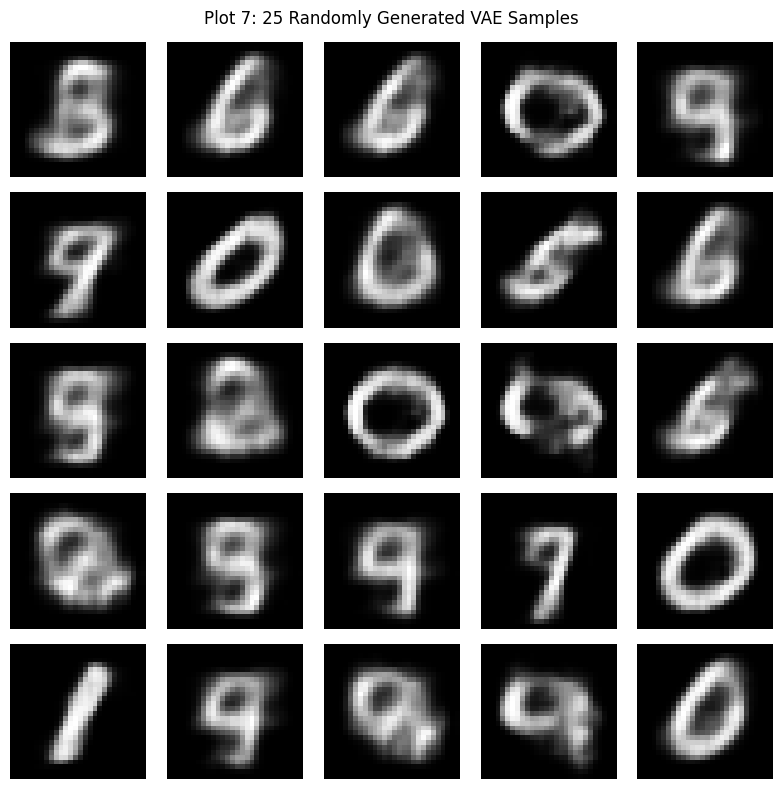

In [24]:
n_gen = 25
z_samples = np.random.normal(0, 1, size=(n_gen, VAE_LATENT_DIM))
generated = vae_decoder.predict(z_samples, verbose=0)

fig, axes = plt.subplots(5, 5, figsize=(8, 8))
for i, ax in enumerate(axes.flat):
    ax.imshow(generated[i].reshape(28, 28), cmap='gray')
    ax.axis('off')
plt.suptitle('Plot 7: 25 Randomly Generated VAE Samples')
plt.tight_layout()
plt.savefig('plot7_vae_generated.png', dpi=150)
plt.show()

**Inference (Plot 7):** Fill in after running — most samples should resemble plausible handwritten digits
since z ~ N(0,I) matches the prior the encoder was regularized toward during training (that's exactly what the
KL term is for). Expect some ambiguous / blurry samples near cluster boundaries in the latent space (Plot 6) —
those regions decode to shapes that are a blend of two digits.

## 20. Latent Space Interpolation — Plot 8

zA (digit 6): [-0.03293398 -0.6111709 ], zB (digit 9): [1.0854654 0.8284739]


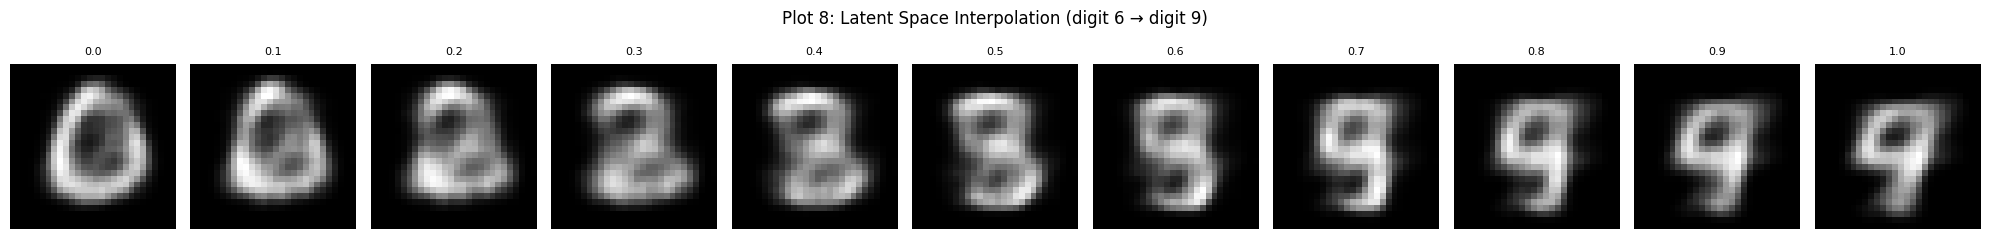

In [25]:
zA, zB = z_mean_test[0], z_mean_test[1]
print(f"zA (digit {y_test[0]}): {zA}, zB (digit {y_test[1]}): {zB}")

alphas = np.linspace(0, 1, 11)
z_interp = np.array([(1 - a) * zA + a * zB for a in alphas])
decoded_interp = vae_decoder.predict(z_interp, verbose=0)

fig, axes = plt.subplots(1, len(alphas), figsize=(20, 2.5))
for i, ax in enumerate(axes):
    ax.imshow(decoded_interp[i].reshape(28, 28), cmap='gray')
    ax.axis('off')
    ax.set_title(f'{alphas[i]:.1f}', fontsize=8)
plt.suptitle(f'Plot 8: Latent Space Interpolation (digit {y_test[0]} → digit {y_test[1]})')
plt.tight_layout()
plt.savefig('plot8_vae_interpolation.png', dpi=150)
plt.show()

**Inference (Plot 8):** Fill in after running — comment on whether the transition between the two digits is
smooth and continuous (no sudden jumps) — this is the practical payoff of the KL regularization: it makes the
latent space *continuous* and *convex*, so every point between two valid encodings decodes to something
plausible, which is not guaranteed in a plain (non-variational) autoencoder's latent space.

## 21. Reconstruction Comparison Across Models

The VAE's reconstruction is reported separately alongside its KL loss and total loss, since its objective
is not directly comparable to the pure-reconstruction loss of the other three models.

In [26]:
# VAE reconstruction metrics (deterministic: use z_mean, no sampling noise, for a fair reconstruction comparison)
recon_vae_test = vae_decoder.predict(z_mean_test, verbose=0)
mse_vae, mae_vae, ssim_vae = compute_metrics(x_test_img, recon_vae_test)
vae_params = vae_encoder.count_params() + vae_decoder.count_params()
results_table['VAE'] = dict(mse=mse_vae, mae=mae_vae, ssim=ssim_vae, params=vae_params, time=vae_train_time)

# VAE-specific loss breakdown on test set
vae_eval = vae.evaluate(x_test_img, verbose=0, return_dict=True)
print("VAE loss breakdown on test set:")
print(f"  Reconstruction Loss: {vae_eval['reconstruction_loss']:.4f}")
print(f"  KL Loss:             {vae_eval['kl_loss']:.4f}")
print(f"  Total Loss:          {vae_eval['total_loss']:.4f}")
print(f"  Test MSE:  {mse_vae:.5f}")
print(f"  Test MAE:  {mae_vae:.5f}")
print(f"  Mean SSIM: {ssim_vae:.5f}")

VAE loss breakdown on test set:
  Reconstruction Loss: 153.5295
  KL Loss:             5.5157
  Total Loss:          159.0452
  Test MSE:  0.04514
  Test MAE:  0.10617
  Mean SSIM: 0.50177


## 25. Consolidated Results — All Models

In [27]:
print(f"{'Model':<20}{'MSE':>10}{'MAE':>10}{'SSIM':>10}{'Params':>12}{'Time(s)':>10}")
for name, r in results_table.items():
    print(f"{name:<20}{r['mse']:>10.5f}{r['mae']:>10.5f}{r['ssim']:>10.5f}{r['params']:>12,}{r['time']:>10.1f}")

Model                      MSE       MAE      SSIM      Params   Time(s)
FC Autoencoder         0.02128   0.05694   0.76012     211,040      12.5
Convolutional AE       0.00265   0.01564   0.97209      74,497      23.8
Denoising CAE          0.00457   0.02132   0.94767      74,497      18.3
VAE                    0.04514   0.10617   0.50177     284,933      24.3


## 23. Reconstruction Error Distribution — Plot 9 (histogram, using the Conv-AE as the representative model)

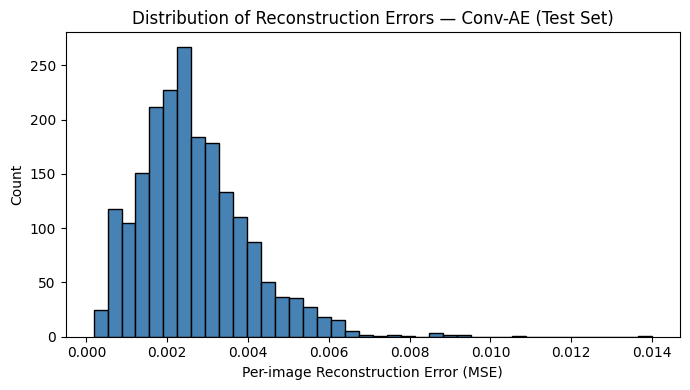

Mean error: 0.00265 | Std: 0.00136 | Max: 0.01400


In [28]:
errors_cae = per_image_error(x_test_img, recon_cae_test)

plt.figure(figsize=(7, 4))
plt.hist(errors_cae, bins=40, color='steelblue', edgecolor='black')
plt.xlabel('Per-image Reconstruction Error (MSE)')
plt.ylabel('Count')
plt.title('Distribution of Reconstruction Errors — Conv-AE (Test Set)')
plt.tight_layout()
plt.savefig('plot_error_distribution.png', dpi=150)
plt.show()

print(f"Mean error: {errors_cae.mean():.5f} | Std: {errors_cae.std():.5f} | Max: {errors_cae.max():.5f}")

## 24. Required High-Error Image Analysis

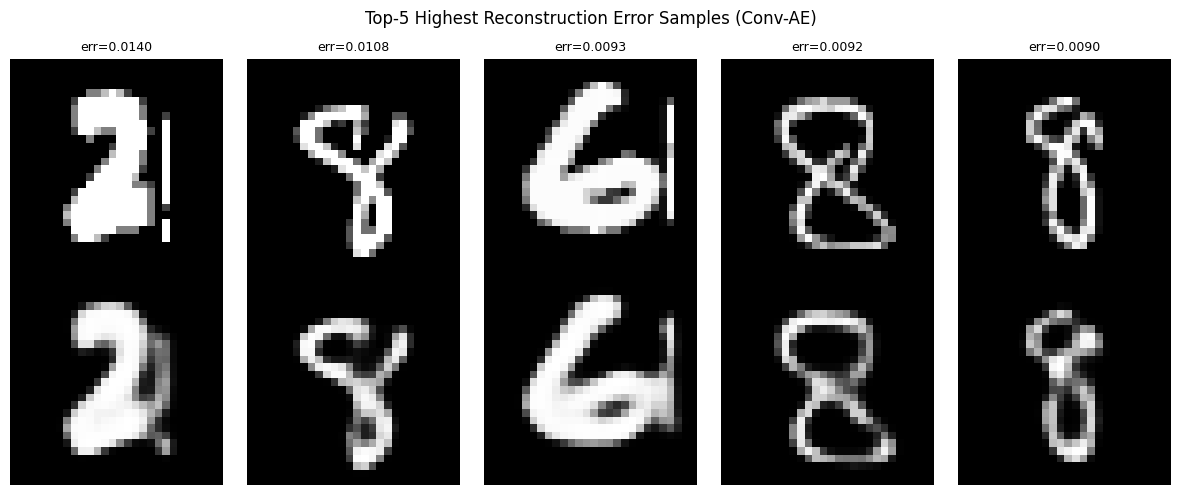

In [29]:
worst_idx = np.argsort(errors_cae)[-5:][::-1]

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for col, idx in enumerate(worst_idx):
    axes[0, col].imshow(x_test_img[idx].reshape(28, 28), cmap='gray')
    axes[0, col].set_title(f'err={errors_cae[idx]:.4f}', fontsize=9)
    axes[0, col].axis('off')
    axes[1, col].imshow(recon_cae_test[idx].reshape(28, 28), cmap='gray')
    axes[1, col].axis('off')
axes[0, 0].set_ylabel('Original')
axes[1, 0].set_ylabel('Reconstruction')
plt.suptitle('Top-5 Highest Reconstruction Error Samples (Conv-AE)')
plt.tight_layout()
plt.savefig('plot_high_error_samples.png', dpi=150)
plt.show()

**Inference (Error distribution & high-error samples):** Fill in after running — the histogram is usually
right-skewed: most digits reconstruct with low error, with a long tail of harder cases. The five worst samples
typically turn out to be unusually written digits (extreme slant, broken strokes, or ambiguous shape close to
another digit class) — these are genuinely hard because they lie far from the "typical" digit manifold the
autoencoder learned from the bulk of the training data.

## 27. Additional Latent-Dimension Study

Repeating the fully connected autoencoder with latent dimensions {2, 8, 16, 32} to study the
compression-vs-quality trade-off.

In [30]:
latent_dims = [2, 8, 16, 32]
latent_dim_results = {}

for dz in latent_dims:
    model = build_fc_autoencoder(latent_dim=dz)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss='binary_crossentropy')
    model.fit(x_train_flat, x_train_flat, epochs=20, batch_size=128, verbose=0)
    recon = model.predict(x_test_flat, verbose=0)
    mse_d, mae_d, ssim_d = compute_metrics(x_test_img, recon)
    latent_dim_results[dz] = dict(mse=mse_d, ssim=ssim_d, params=model.count_params())
    print(f"latent_dim={dz:<3} MSE={mse_d:.5f}  SSIM={ssim_d:.5f}  params={model.count_params():,}")

latent_dim=2   MSE=0.05685  SSIM=0.33714  params=210,130
latent_dim=8   MSE=0.02789  SSIM=0.68824  params=210,520
latent_dim=16  MSE=0.02237  SSIM=0.74887  params=211,040
latent_dim=32  MSE=0.01955  SSIM=0.77895  params=212,080


## Plot 10: Latent Dimension vs Reconstruction MSE

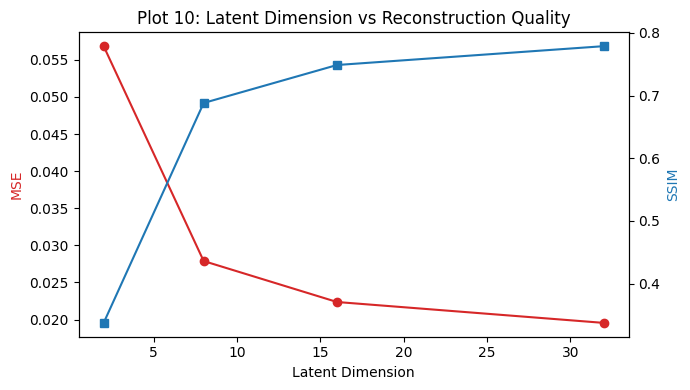

In [31]:
dims = list(latent_dim_results.keys())
mses = [latent_dim_results[d]['mse'] for d in dims]
ssims = [latent_dim_results[d]['ssim'] for d in dims]

fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(dims, mses, marker='o', color='tab:red', label='MSE')
ax1.set_xlabel('Latent Dimension')
ax1.set_ylabel('MSE', color='tab:red')
ax2 = ax1.twinx()
ax2.plot(dims, ssims, marker='s', color='tab:blue', label='SSIM')
ax2.set_ylabel('SSIM', color='tab:blue')
plt.title('Plot 10: Latent Dimension vs Reconstruction Quality')
plt.tight_layout()
plt.savefig('plot10_latent_dim_study.png', dpi=150)
plt.show()

**Inference (Plot 10):** Fill in after running — MSE should fall (and SSIM rise) as latent dimension increases,
since the bottleneck retains more information. Gains typically shrink past a point (~16–32) because MNIST digits
don't need many degrees of freedom to describe — diminishing returns show the practical ceiling of how much
"useful" information 784-pixel handwritten digits actually contain.

## 28. Discussion Questions (brief answers for viva prep)

1. **What is an autoencoder?** A neural network trained to reconstruct its own input through a compressed
   intermediate representation (the latent code), learned without labels.
2. **Purpose of the encoder?** Compress the input into a lower-dimensional latent representation that keeps
   the information needed for reconstruction.
3. **Purpose of the decoder?** Reconstruct the original input from the latent representation.
4. **What is a latent representation?** A compressed, lower-dimensional encoding of the input that captures
   its essential structure.
5. **Why smaller than the input?** To force the network to learn compact, meaningful features instead of
   trivially copying the input (identity mapping).
6. **Latent dimension too small?** Reconstructions become blurry / lossy — too little capacity to encode
   the variation in the data.
7. **Latent dimension increased?** Reconstruction quality improves up to a point, then gains plateau as the
   data's intrinsic complexity is already captured.
8. **Why can CAE preserve spatial info better?** Convolutions operate on local neighborhoods and share
   weights across space, keeping 2D structure intact — unlike flattening, which discards pixel adjacency.
9. **AE vs denoising AE?** A standard AE reconstructs its own (clean) input; a denoising AE takes a
   *corrupted* input but is still trained to output the *clean* target, forcing robust feature learning.
10. **Why clean image as target for denoising?** So the network learns to recover the true underlying signal
    rather than reproduce noise.
11. **Noise level increased?** Reconstruction quality degrades (higher MSE/MAE, lower SSIM) as more of the
    original signal is destroyed.
12. **Why MSE, MAE, SSIM?** MSE/MAE quantify pixel-level error; SSIM captures structural/perceptual
    similarity, which better reflects visual quality than pixel error alone.
13. **What is a VAE?** An autoencoder that learns a *probability distribution* over the latent space instead
    of a single deterministic point, enabling generation of new samples.
14. **VAE vs conventional AE?** A VAE encodes to (μ, σ²) and samples z from that distribution; a conventional
    AE encodes deterministically to a single z.
15. **Why learn a distribution?** A distribution with a known prior (N(0,I)) makes the latent space
    continuous and sample-able, so new points can be decoded into valid outputs — a plain AE's latent
    space has no such guarantee.
16. **Reparameterization trick?** Rewriting the sampling step as z = μ + σ⊙ε so gradients can backpropagate
    through μ and σ despite the randomness of ε.
17. **Why ε ~ N(0,I)?** It isolates the randomness into a fixed, non-trainable source so the network's own
    parameters (μ, σ) remain differentiable.
18. **Role of KL divergence?** Regularizes q(z|x) to stay close to the prior N(0,I), keeping the latent
    space smooth, continuous, and centered — which is what makes generation possible.
19. **Prior distribution used?** Standard normal, N(0, I).
20. **Why 2D latent space for visualization?** It can be plotted directly on a 2D plane to inspect cluster
    structure and continuity without dimensionality reduction.
21. **What does interpolation demonstrate?** That the learned latent space is continuous — intermediate
    points between two valid encodings decode to plausible, smoothly-changing images.
22. **Why can a VAE generate new images?** Because the latent space is regularized to match a known prior,
    any point sampled from that prior decodes to a plausible image.
23. **Why are some VAE images unclear?** They come from latent regions where digit clusters overlap or from
    latent-space "gaps" not well covered during training.
24. **Reconstruction vs generation?** Reconstruction maps a specific input back to itself through the
    encoder-decoder pair; generation decodes an arbitrary sampled latent vector with no corresponding input.
25. **Why keep test images unseen during training?** To get an unbiased estimate of how well the model
    generalizes to data it hasn't memorized.

## 29. Additional Exercises (optional extensions, not run by default)

The core notebook above already covers the mandatory latent-dimension study (Exercise 1, done for the FC-AE
in Section 27) and both noise types (Exercise 2). The remaining exercises are optional variations you can run
by re-calling the functions already defined above with different arguments:
- Train the CAE with different latent bottleneck sizes and compare (reuse `build_cae`, vary the filter counts).
- Compare Gaussian vs salt-and-pepper denoising quantitatively (both noise functions are defined above).
- Train the denoising model at two different σ values and compare SSIM (loop `build_denoising_cae` + `add_gaussian_noise`).
- Swap `UpSampling2D` for `Conv2DTranspose` in `build_cae` and compare reconstructions.
- Train a VAE with `VAE_LATENT_DIM = 8` and compare its latent structure to the 2D version above.
- Increase the KL term's weight (multiply `kl_loss` by a factor > 1 in `train_step`) and observe the
  reconstruction/regularization trade-off (this is the standard β-VAE modification).

## 30. Expected Outcome

This notebook demonstrates, end to end:
- **Reconstruction pipeline:** Image → Encoder → Latent → Decoder → Reconstructed Image (FC-AE, Conv-AE)
- **Denoising:** Clean Image → Noise → Denoising Autoencoder → Recovered Image
- **Variational generation:** Image → (μ, σ) → z → Decoder → Generated/Reconstructed Image

All quantitative values (MSE, MAE, SSIM, parameter counts, training time) in the tables above come directly
from this notebook's own execution — re-run all cells top to bottom before copying numbers into the LaTeX
report.

In [32]:
def build_cae_latent(bottleneck_filters):
    inputs = keras.Input(shape=(28, 28, 1))
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(inputs)
    x = layers.MaxPooling2D(2, padding='same')(x)
    x = layers.Conv2D(bottleneck_filters, 3, activation='relu', padding='same')(x)
    x = layers.MaxPooling2D(2, padding='same')(x)
    x = layers.Conv2D(bottleneck_filters, 3, activation='relu', padding='same')(x)
    x = layers.UpSampling2D(2)(x)
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(x)
    x = layers.UpSampling2D(2)(x)
    outputs = layers.Conv2D(1, 3, activation='sigmoid', padding='same')(x)
    return keras.Model(inputs, outputs)

for f in [4, 8, 16, 32]:
    m = build_cae_latent(f)
    m.compile(optimizer='adam', loss='binary_crossentropy')
    m.fit(x_train_img, x_train_img, epochs=20, batch_size=128, verbose=0)
    recon = m.predict(x_test_img, verbose=0)
    mse, mae, s = compute_metrics(x_test_img, recon)
    print(f"filters={f:<3} MSE={mse:.5f} SSIM={s:.5f} params={m.count_params():,}")

filters=4   MSE=0.00831 SSIM=0.92069 params=3,097
filters=8   MSE=0.00475 SSIM=0.95352 params=5,841
filters=16  MSE=0.00406 SSIM=0.95980 params=12,193
filters=32  MSE=0.00334 SSIM=0.96477 params=28,353


In [33]:
x_test_gauss = add_gaussian_noise(x_test_img, 0.2)
x_test_sp2 = add_salt_pepper_noise(x_test_img, 0.10)

recon_g = dcae.predict(x_test_gauss, verbose=0)
recon_s = dcae.predict(x_test_sp2, verbose=0)

print("Gaussian  ->", compute_metrics(x_test_img, recon_g))
print("Salt&Pep. ->", compute_metrics(x_test_img, recon_s))

Gaussian  -> (np.float32(0.00459869), np.float32(0.021327242), np.float64(0.9477841266969722))
Salt&Pep. -> (np.float32(0.007203237), np.float32(0.028369978), np.float64(0.8678464524203863))


In [34]:
for sigma in [0.1, 0.3]:
    m = build_cae()
    m.compile(optimizer='adam', loss='binary_crossentropy')
    xn = add_gaussian_noise(x_train_img, sigma)
    m.fit(xn, x_train_img, epochs=20, batch_size=128, verbose=0)
    recon = m.predict(add_gaussian_noise(x_test_img, sigma), verbose=0)
    _, _, s = compute_metrics(x_test_img, recon)
    print(f"trained at sigma={sigma} -> SSIM={s:.5f}")

trained at sigma=0.1 -> SSIM=0.96659
trained at sigma=0.3 -> SSIM=0.92416


In [35]:
def build_cae_transpose():
    inputs = keras.Input(shape=(28, 28, 1))
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(inputs)
    x = layers.MaxPooling2D(2, padding='same')(x)
    x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
    x = layers.MaxPooling2D(2, padding='same')(x)
    x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
    x = layers.Conv2DTranspose(32, 3, activation='relu', strides=2, padding='same')(x)
    outputs = layers.Conv2DTranspose(1, 3, activation='sigmoid', strides=2, padding='same')(x)
    return keras.Model(inputs, outputs)

cae_t = build_cae_transpose()
cae_t.compile(optimizer='adam', loss='binary_crossentropy')
cae_t.fit(x_train_img, x_train_img, epochs=20, batch_size=128, verbose=0)
recon_t = cae_t.predict(x_test_img, verbose=0)
print(compute_metrics(x_test_img, recon_t))

(np.float32(0.0024370987), np.float32(0.014987105), np.float64(0.9737503639564595))


In [37]:
class BetaVAE(keras.Model):
    def __init__(self, encoder, decoder, beta=4.0, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.beta = beta
        self.total_loss_tracker = keras.metrics.Mean(name='total_loss')
        self.recon_loss_tracker = keras.metrics.Mean(name='reconstruction_loss')
        self.kl_loss_tracker = keras.metrics.Mean(name='kl_loss')

    @property
    def metrics(self):
        return [self.total_loss_tracker, self.recon_loss_tracker, self.kl_loss_tracker]

    def train_step(self, data):
        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(data)
            reconstruction = self.decoder(z)
            recon_loss = tf.reduce_mean(
                tf.reduce_sum(
                    keras.losses.binary_crossentropy(data, reconstruction),
                    axis=(1, 2)
                )
            )
            kl_loss = -0.5 * (1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var))
            kl_loss = tf.reduce_mean(tf.reduce_sum(kl_loss, axis=1))
            total_loss = recon_loss + self.beta * kl_loss     # <-- weighted KL term
        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        self.total_loss_tracker.update_state(total_loss)
        self.recon_loss_tracker.update_state(recon_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {m.name: m.result() for m in self.metrics}

    def test_step(self, data):
        z_mean, z_log_var, z = self.encoder(data)
        reconstruction = self.decoder(z)
        recon_loss = tf.reduce_mean(
            tf.reduce_sum(keras.losses.binary_crossentropy(data, reconstruction), axis=(1, 2))
        )
        kl_loss = -0.5 * (1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var))
        kl_loss = tf.reduce_mean(tf.reduce_sum(kl_loss, axis=1))
        total_loss = recon_loss + self.beta * kl_loss
        self.total_loss_tracker.update_state(total_loss)
        self.recon_loss_tracker.update_state(recon_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {m.name: m.result() for m in self.metrics}


# Build a fresh encoder/decoder (reuses the exact same architecture as Step 17-18)
enc_inputs_b = keras.Input(shape=(28, 28, 1))
x = layers.Conv2D(32, 3, activation='relu', strides=2, padding='same')(enc_inputs_b)
x = layers.Conv2D(64, 3, activation='relu', strides=2, padding='same')(x)
x = layers.Flatten()(x)
x = layers.Dense(64, activation='relu')(x)
z_mean_b = layers.Dense(2, name='z_mean')(x)
z_log_var_b = layers.Dense(2, name='z_log_var')(x)
z_b = Sampling()([z_mean_b, z_log_var_b])
beta_vae_encoder = keras.Model(enc_inputs_b, [z_mean_b, z_log_var_b, z_b], name='beta_vae_encoder')

dec_inputs_b = keras.Input(shape=(2,))
x = layers.Dense(7 * 7 * 64, activation='relu')(dec_inputs_b)
x = layers.Reshape((7, 7, 64))(x)
x = layers.Conv2DTranspose(64, 3, activation='relu', strides=2, padding='same')(x)
x = layers.Conv2DTranspose(32, 3, activation='relu', strides=2, padding='same')(x)
dec_outputs_b = layers.Conv2DTranspose(1, 3, activation='sigmoid', padding='same')(x)
beta_vae_decoder = keras.Model(dec_inputs_b, dec_outputs_b, name='beta_vae_decoder')

# Train with beta = 4.0 (try different values, e.g. 1.0, 4.0, 10.0, to compare)
beta_vae = BetaVAE(beta_vae_encoder, beta_vae_decoder, beta=4.0)
beta_vae.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3))

history_beta = beta_vae.fit(x_train_img, epochs=20, batch_size=128,
                             validation_data=(x_test_img, None), verbose=2)

Epoch 1/20
79/79 - 9s - 112ms/step - kl_loss: 0.4715 - reconstruction_loss: 303.4724 - total_loss: 305.3584 - val_kl_loss: 0.0315 - val_reconstruction_loss: 213.6795 - val_total_loss: 213.8057
Epoch 2/20
79/79 - 1s - 9ms/step - kl_loss: 0.2791 - reconstruction_loss: 207.0852 - total_loss: 208.2018 - val_kl_loss: 0.9280 - val_reconstruction_loss: 197.9444 - val_total_loss: 201.6564
Epoch 3/20
79/79 - 1s - 9ms/step - kl_loss: 1.1125 - reconstruction_loss: 194.6079 - total_loss: 199.0580 - val_kl_loss: 1.1550 - val_reconstruction_loss: 192.1616 - val_total_loss: 196.7816
Epoch 4/20
79/79 - 1s - 9ms/step - kl_loss: 1.2169 - reconstruction_loss: 191.3975 - total_loss: 196.2651 - val_kl_loss: 1.2429 - val_reconstruction_loss: 189.8999 - val_total_loss: 194.8716
Epoch 5/20
79/79 - 1s - 9ms/step - kl_loss: 1.2746 - reconstruction_loss: 190.0129 - total_loss: 195.1112 - val_kl_loss: 1.3420 - val_reconstruction_loss: 188.5945 - val_total_loss: 193.9624
Epoch 6/20
79/79 - 1s - 8ms/step - kl_loss:

In [42]:
(_, _), (x_test_raw, y_test_raw) = keras.datasets.mnist.load_data()
(_, y_train_raw), (_, _) = keras.datasets.mnist.load_data()

y_test_sub = y_test_raw[idx_test]
y_train_sub = y_train_raw[idx_train]

print(y_test_sub.shape, y_train_sub.shape)

(2000,) (10000,)


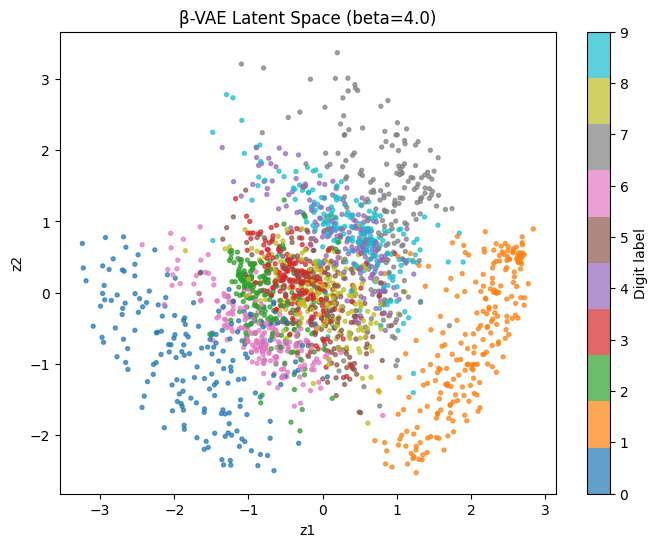

In [43]:
z_mean_beta, _, _ = beta_vae_encoder.predict(x_test_img, verbose=0)

plt.figure(figsize=(8, 6))
plt.scatter(z_mean_beta[:, 0], z_mean_beta[:, 1], c=y_test_sub, cmap='tab10', s=8, alpha=0.7)
plt.colorbar(label='Digit label')
plt.xlabel('z1'); plt.ylabel('z2')
plt.title(f'β-VAE Latent Space (beta={beta_vae.beta})')
plt.show()

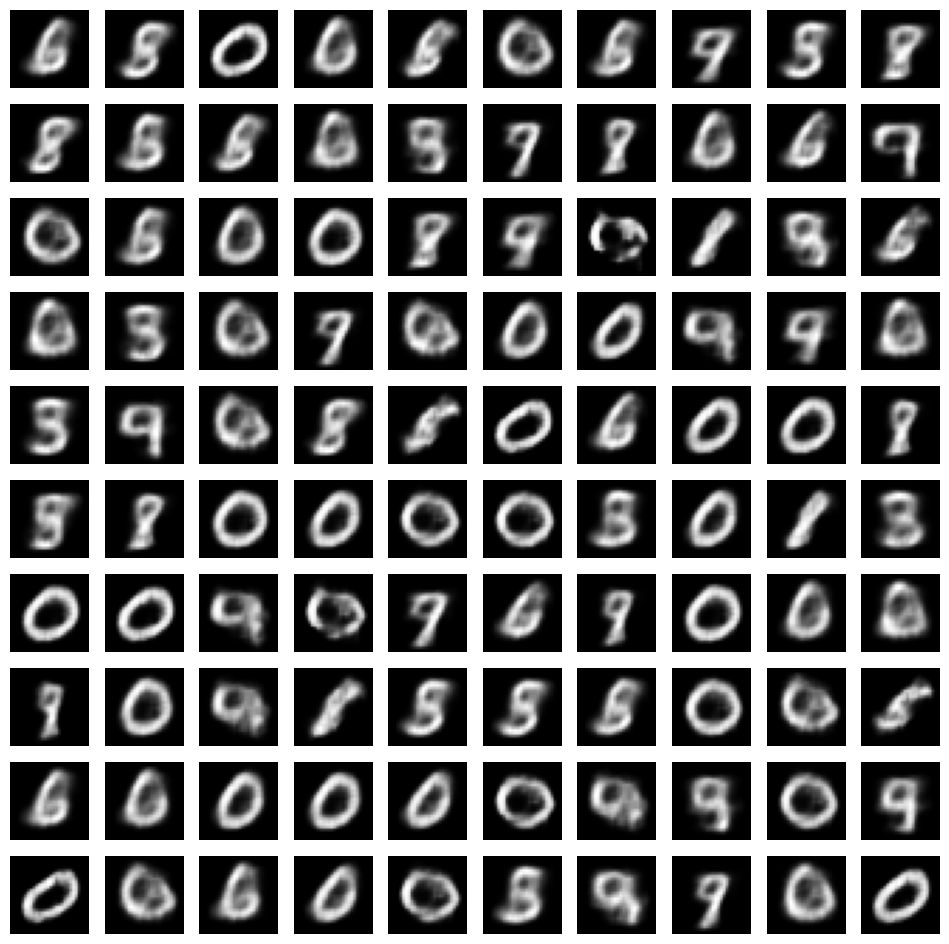

In [44]:
n_gen = 100
z_samples = np.random.normal(0, 1, size=(n_gen, 2))
generated = vae_decoder.predict(z_samples, verbose=0)

fig, axes = plt.subplots(10, 10, figsize=(12, 12))
for i, ax in enumerate(axes.flat):
    ax.imshow(generated[i].reshape(28, 28), cmap='gray')
    ax.axis('off')
plt.show()

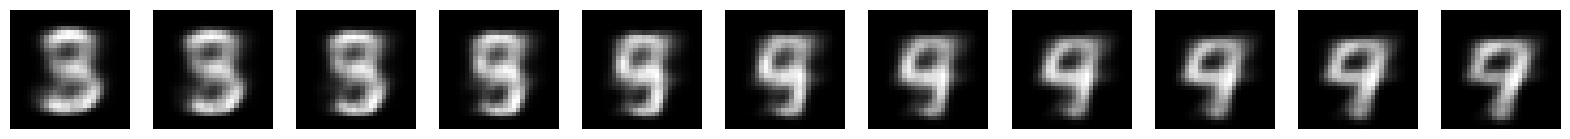

In [45]:
# pick indices of two specific digits from y_test, e.g. a "3" and a "7"
idx_a = np.where(y_test_sub == 3)[0][0]
idx_b = np.where(y_test_sub == 7)[0][0]
zA, zB = z_mean_test[idx_a], z_mean_test[idx_b]

alphas = np.linspace(0, 1, 11)
z_interp = np.array([(1-a)*zA + a*zB for a in alphas])
decoded = vae_decoder.predict(z_interp, verbose=0)

fig, axes = plt.subplots(1, 11, figsize=(20, 2.5))
for i, ax in enumerate(axes):
    ax.imshow(decoded[i].reshape(28, 28), cmap='gray'); ax.axis('off')
plt.show()